In [1]:
import sys
from pathlib import Path

# Add project root to sys.path so we can import from utils
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from utils.plotting import PALETTE, plot_cdf, plot_pdf, set_style

# Apply standard style across all plots
set_style()

# Normal (Gaussian) Distribution: The Central Pillar of Statistics

## 1. Intuition & Motivation

Why is the bell curve everywhere?
- Human heights, blood pressures, and birth weights.
- Measurement errors in astronomy and laboratory physics.
- Daily financial market log-returns and temperature anomalies.
- Test scores, manufacturing tolerances, and noise in audio signals.

The **Normal (Gaussian) distribution** appears so universally not because nature chose a favorite formula, but because of a mathematical law of nature:
Whenever an observed quantity is the **sum or average of many small, independent random factors**, its distribution inevitably converges to a bell curve—regardless of the distributions of the individual factors!

This is the **Central Limit Theorem (CLT)**.

### Historical Device: The Galton Board (Quincunx)
In 1873, Sir Francis Galton built a vertical board with rows of interleaved pins. Marbles are dropped from the top; at each pin, a marble bounces randomly left ($-1$) or right ($+1$) with equal probability. By the time the marbles reach the bottom bins, their accumulated independent bounces form a bell curve.

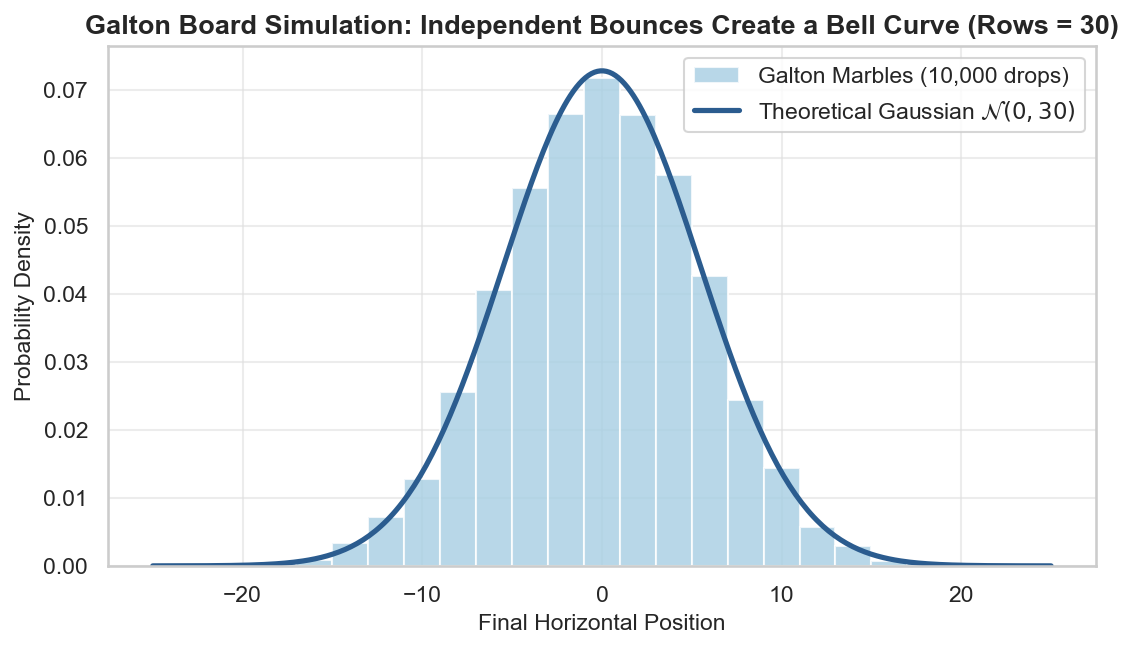

Sample Mean Position: 0.005 (Theoretical: 0.0)
Sample Std Deviation: 5.498 (Theoretical: 5.477)


In [2]:
# Galton Board parameters
n_rows = 30  # Number of pin layers
n_marbles = 10000  # Number of dropped marbles

# Seed for reproducibility
rng = np.random.default_rng(seed=42)

# At each pin, marble bounces -1 (left) or +1 (right) with 50% chance
# Shape: (10000 marbles, 30 pin rows)
bounces = rng.choice([-1, 1], size=(n_marbles, n_rows))

# The final horizontal position is the sum of all 30 bounces
final_positions = np.sum(bounces, axis=1)

# Theoretical Gaussian parameters by CLT:
# Mean = 0, Variance = n_rows * Var(one bounce) = 30 * 1 = 30
mu_clt = 0.0
sigma_clt = np.sqrt(n_rows)  # sqrt(30) ≈ 5.477

# Plot empirical marble positions vs theoretical Gaussian curve
plt.figure(figsize=(8.5, 4.5))
plt.hist(
    final_positions,
    bins=np.arange(
        min(final_positions) - 1, max(final_positions) + 3, 2
    ),
    density=True,
    color=PALETTE["fill"],
    edgecolor="white",
    alpha=0.8,
    label=f"Galton Marbles ({n_marbles:,} drops)",
)

x_bell = np.linspace(-25, 25, 300)
pdf_bell = stats.norm.pdf(x_bell, loc=mu_clt, scale=sigma_clt)
plt.plot(
    x_bell,
    pdf_bell,
    color=PALETTE["primary"],
    linewidth=2.5,
    label=rf"Theoretical Gaussian $\mathcal{{N}}(0, {n_rows})$",
)

plt.title(
    f"Galton Board Simulation: Independent Bounces Create a Bell Curve (Rows = {n_rows})",
    weight="bold",
)
plt.xlabel("Final Horizontal Position")
plt.ylabel("Probability Density")
plt.legend(frameon=True)
plt.show()

print(f"Sample Mean Position: {np.mean(final_positions):.3f} (Theoretical: {mu_clt:.1f})")
print(f"Sample Std Deviation: {np.std(final_positions, ddof=1):.3f} (Theoretical: {sigma_clt:.3f})")

## 2. Mathematical Definition

A continuous random variable $X$ follows a Normal (Gaussian) distribution with mean $\mu$ and standard deviation $\sigma$, written:
$$X \sim \mathcal{N}(\mu, \sigma^2)$$

### Parameters & Support
- **$\mu \in \mathbb{R}$**: Location parameter (mean, median, and mode).
- **$\sigma > 0$**: Scale parameter (standard deviation; $\sigma^2$ is variance).
- **Support**: The entire real line: $x \in (-\infty, +\infty)$.

### Probability Density Function (PDF)
$$f(x) = \frac{1}{\sigma \sqrt{2\pi}} \exp\left( -\frac{1}{2} \left(\frac{x - \mu}{\sigma}\right)^2 \right)$$

### Cumulative Distribution Function (CDF) & The Error Function
Because $e^{-t^2}$ has no elementary antiderivative, the CDF is expressed using the Gauss **error function** $\text{erf}(z) = \frac{2}{\sqrt{\pi}}\int_0^z e^{-t^2} dt$:
$$F(x) = P(X \le x) = \frac{1}{2} \left[ 1 + \text{erf}\left( \frac{x - \mu}{\sigma \sqrt{2}} \right) \right]$$

### Standardization (Z-score)
Any normal variable can be converted into the **Standard Normal distribution** $\mathcal{N}(0, 1)$ by standardizing:
$$Z = \frac{X - \mu}{\sigma} \sim \mathcal{N}(0, 1)$$

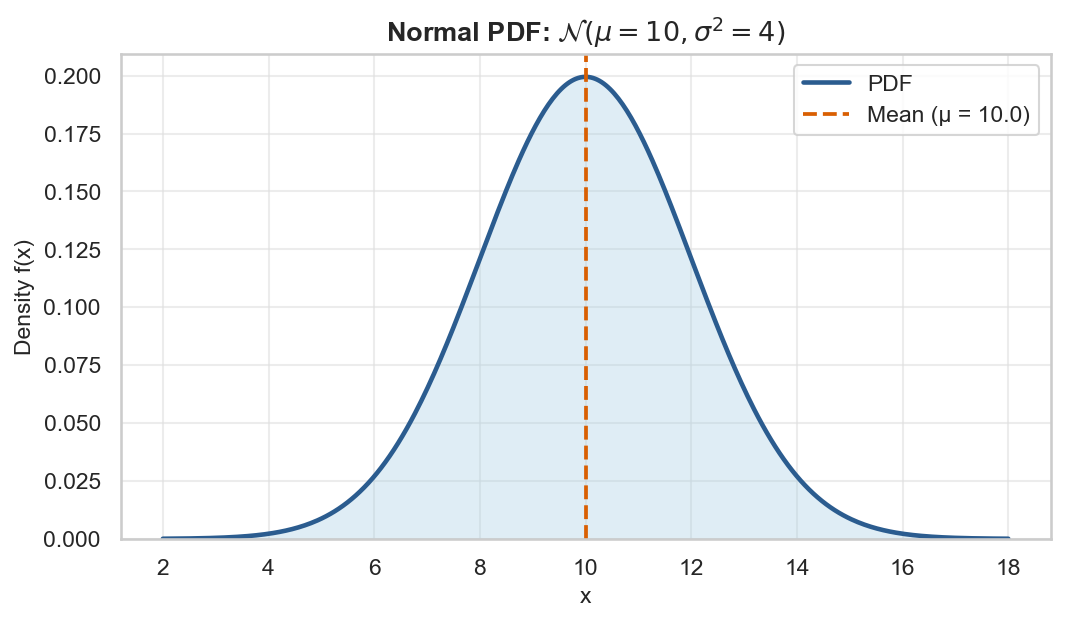

In [3]:
# Parameters
mu = 10.0
sigma = 2.0

# Evaluation range spanning mu +/- 4*sigma
x_axis = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 400)
pdf_vals = stats.norm.pdf(x_axis, loc=mu, scale=sigma)

# Plot PDF using our continuous plotting helper
fig, ax = plt.subplots(figsize=(8, 4.2))
plot_pdf(
    x_axis,
    pdf_vals,
    title=rf"Normal PDF: $\mathcal{{N}}(\mu={mu:.0f}, \sigma^2={sigma**2:.0f})$",
    xlabel="x",
    ylabel="Density f(x)",
    fill=True,
    ax=ax,
)
ax.axvline(
    mu,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=1.8,
    label=f"Mean (μ = {mu})",
)
ax.legend(frameon=True)
plt.show()

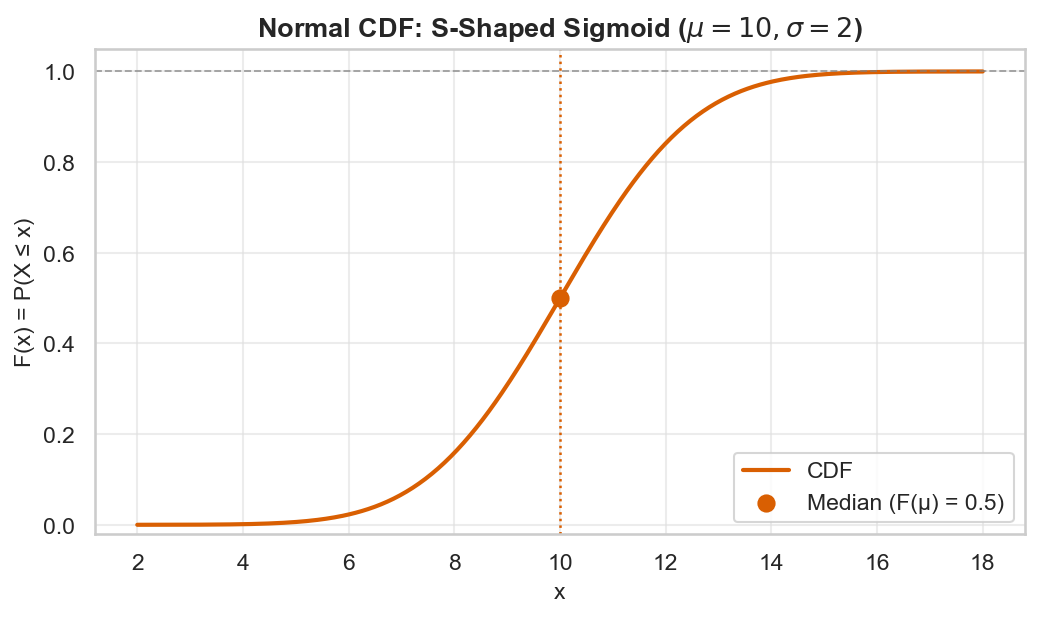

In [4]:
# Evaluate theoretical CDF: F(x) = P(X <= x)
cdf_vals = stats.norm.cdf(x_axis, loc=mu, scale=sigma)

fig, ax = plt.subplots(figsize=(8, 4.2))
plot_cdf(
    x_axis,
    cdf_vals,
    is_discrete=False,
    title=rf"Normal CDF: S-Shaped Sigmoid ($\mu={mu:.0f}, \sigma={sigma:.0f}$)",
    xlabel="x",
    ylabel="F(x) = P(X ≤ x)",
    ax=ax,
)
ax.axvline(mu, color=PALETTE["secondary"], linestyle=":", linewidth=1.2)
ax.scatter([mu], [0.5], color=PALETTE["secondary"], s=60, zorder=5, label="Median (F(μ) = 0.5)")
ax.legend(frameon=True)
plt.show()

## 3. Key Theoretical Properties

The Normal distribution possesses remarkable geometric and statistical symmetries:

### 1. Moments
- **Mean = Median = Mode**: $\mu$ (perfect three-way coincidence).
- **Variance**: $\sigma^2$ (and Standard Deviation $\sigma$).
- **Skewness ($\gamma_1$)**: $0$ (strictly symmetric).
- **Excess Kurtosis ($\gamma_2$)**: $0$ (the baseline definition of **mesokurtic**).

### 2. Inflection Points
The second derivative $f''(x) = 0$ occurs precisely at:
$$x = \mu - \sigma \quad \text{and} \quad x = \mu + \sigma$$
The points where the bell curve changes from convex to concave are exactly **one standard deviation** away from the center!

### 3. The Empirical Rule (68 – 95 – 99.7 Rule)
For any Gaussian variable:
- $\approx \mathbf{68.27\%}$ of all values lie within $\mu \pm 1\sigma$.
- $\approx \mathbf{95.45\%}$ of all values lie within $\mu \pm 2\sigma$.
- $\approx \mathbf{99.73\%}$ of all values lie within $\mu \pm 3\sigma$.
Only $0.27\%$ (roughly 1 in 370) fall beyond 3 standard deviations.

In [5]:
# Verify moments against SciPy
mu_sp, var_sp, skew_sp, kurt_sp = stats.norm.stats(
    loc=mu, scale=sigma, moments="mvsk"
)

print("--- NORMAL THEORETICAL MOMENTS ---")
print(f"Moment               | Analytical | SciPy")
print("-" * 46)
print(f"Mean (μ)             | {mu:10.4f} | {float(mu_sp):10.4f}")
print(f"Variance (σ²)        | {sigma**2:10.4f} | {float(var_sp):10.4f}")
print(f"Std Deviation (σ)    | {sigma:10.4f} | {np.sqrt(float(var_sp)):10.4f}")
print(f"Skewness (γ₁)        | {0.0:10.4f} | {float(skew_sp):10.4f}")
print(f"Excess Kurtosis (γ₂) | {0.0:10.4f} | {float(kurt_sp):10.4f}")

--- NORMAL THEORETICAL MOMENTS ---
Moment               | Analytical | SciPy
----------------------------------------------
Mean (μ)             |    10.0000 |    10.0000
Variance (σ²)        |     4.0000 |     4.0000
Std Deviation (σ)    |     2.0000 |     2.0000
Skewness (γ₁)        |     0.0000 |     0.0000
Excess Kurtosis (γ₂) |     0.0000 |     0.0000


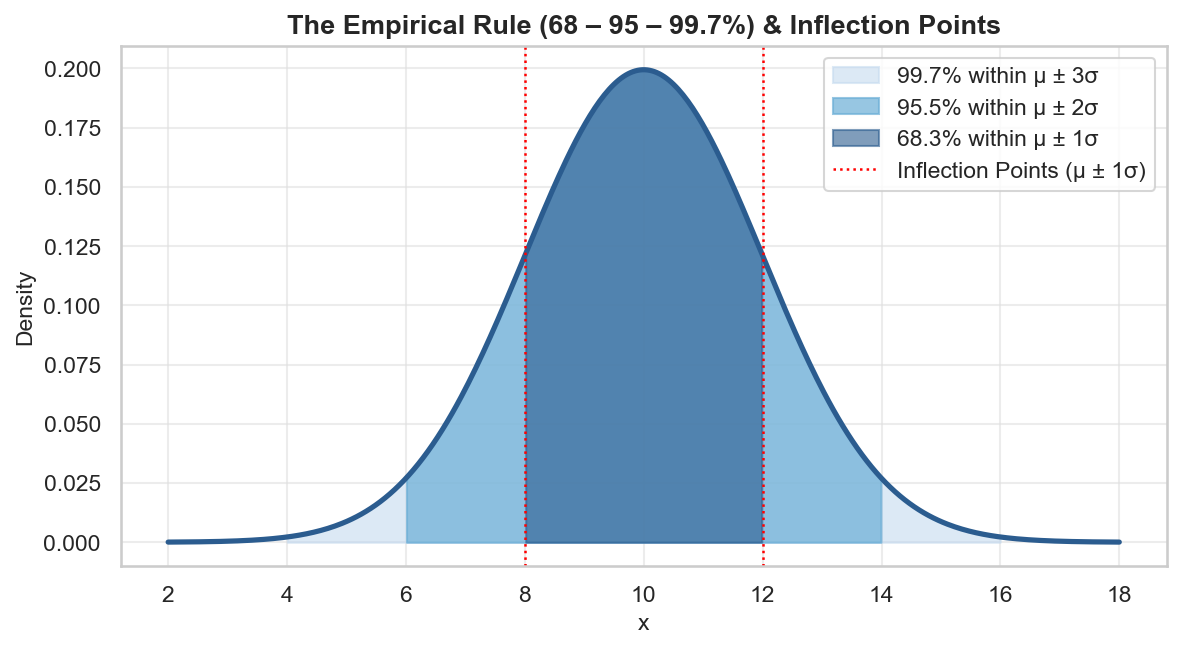

In [6]:
# Visualizing the 68 - 95 - 99.7 Empirical Rule
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(x_axis, pdf_vals, color=PALETTE["primary"], linewidth=2.5)

# Shaded intervals
# 3-Sigma: 99.7%
mask_3s = (x_axis >= mu - 3 * sigma) & (x_axis <= mu + 3 * sigma)
ax.fill_between(
    x_axis[mask_3s],
    pdf_vals[mask_3s],
    color="#c6dbef",
    alpha=0.6,
    label="99.7% within μ ± 3σ",
)

# 2-Sigma: 95.5%
mask_2s = (x_axis >= mu - 2 * sigma) & (x_axis <= mu + 2 * sigma)
ax.fill_between(
    x_axis[mask_2s],
    pdf_vals[mask_2s],
    color="#6baed6",
    alpha=0.7,
    label="95.5% within μ ± 2σ",
)

# 1-Sigma: 68.3%
mask_1s = (x_axis >= mu - 1 * sigma) & (x_axis <= mu + 1 * sigma)
ax.fill_between(
    x_axis[mask_1s],
    pdf_vals[mask_1s],
    color=PALETTE["primary"],
    alpha=0.6,
    label="68.3% within μ ± 1σ",
)

# Mark Inflection Points (mu +/- sigma)
ax.axvline(mu - sigma, color="red", linestyle=":", linewidth=1.2)
ax.axvline(
    mu + sigma,
    color="red",
    linestyle=":",
    linewidth=1.2,
    label="Inflection Points (μ ± 1σ)",
)

ax.set_title("The Empirical Rule (68 – 95 – 99.7%) & Inflection Points", weight="bold")
ax.set_xlabel("x")
ax.set_ylabel("Density")
ax.legend(frameon=True, loc="upper right")
plt.show()

## 4. Parameter Variation

The two parameters cleanly separate location and scale:
1. **Changing $\mu$ (Fixed $\sigma$)**:
   - Slides the entire bell curve horizontally along the x-axis.
   - The height, width, and shape remain identical.
2. **Changing $\sigma$ (Fixed $\mu$)**:
   - Controls the spread and height.
   - **Small $\sigma$ (e.g., $\sigma = 0.8$)**: Tall, narrow, highly concentrated peak.
   - **Large $\sigma$ (e.g., $\sigma = 3.0$)**: Broad, flattened bell curve.
   - The peak height is always inversely proportional to standard deviation: $f(\mu) = \frac{1}{\sigma \sqrt{2\pi}}$.

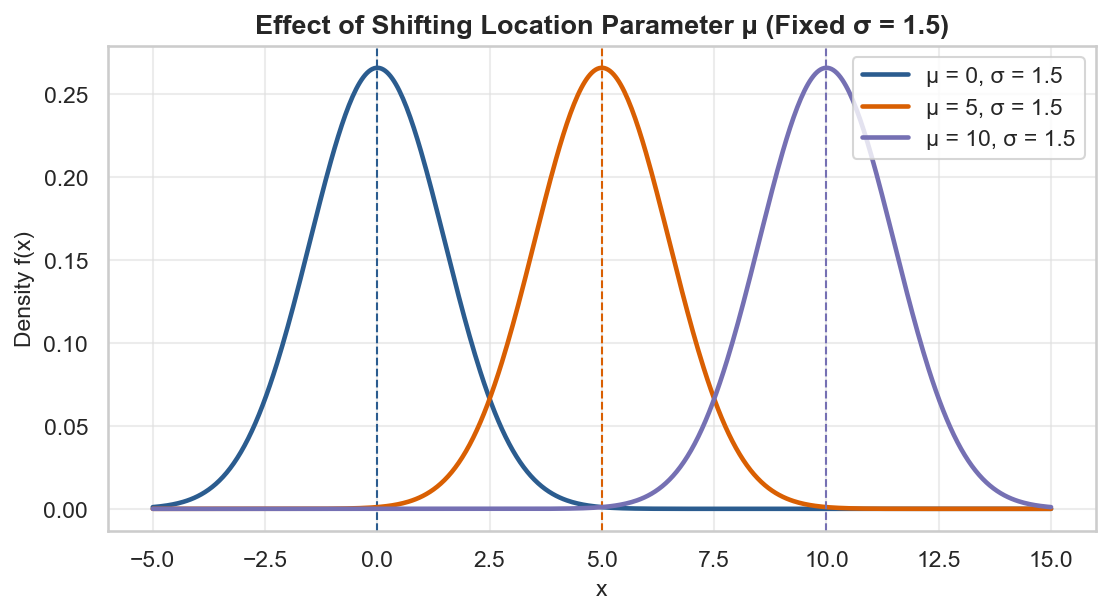

In [7]:
# Varying Mean mu (Fixed sigma = 1.5)
mu_list = [0.0, 5.0, 10.0]
sigma_fixed = 1.5
x_eval_mu = np.linspace(-5, 15, 500)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
colors = [PALETTE["primary"], PALETTE["secondary"], PALETTE["accent"]]

for mu_val, col in zip(mu_list, colors):
    pdf = stats.norm.pdf(x_eval_mu, loc=mu_val, scale=sigma_fixed)
    ax.plot(
        x_eval_mu,
        pdf,
        label=f"μ = {mu_val:.0f}, σ = {sigma_fixed}",
        color=col,
        linewidth=2.2,
    )
    ax.axvline(mu_val, color=col, linestyle="--", linewidth=1.0)

ax.set_title("Effect of Shifting Location Parameter μ (Fixed σ = 1.5)", weight="bold")
ax.set_xlabel("x")
ax.set_ylabel("Density f(x)")
ax.legend(frameon=True)
plt.show()

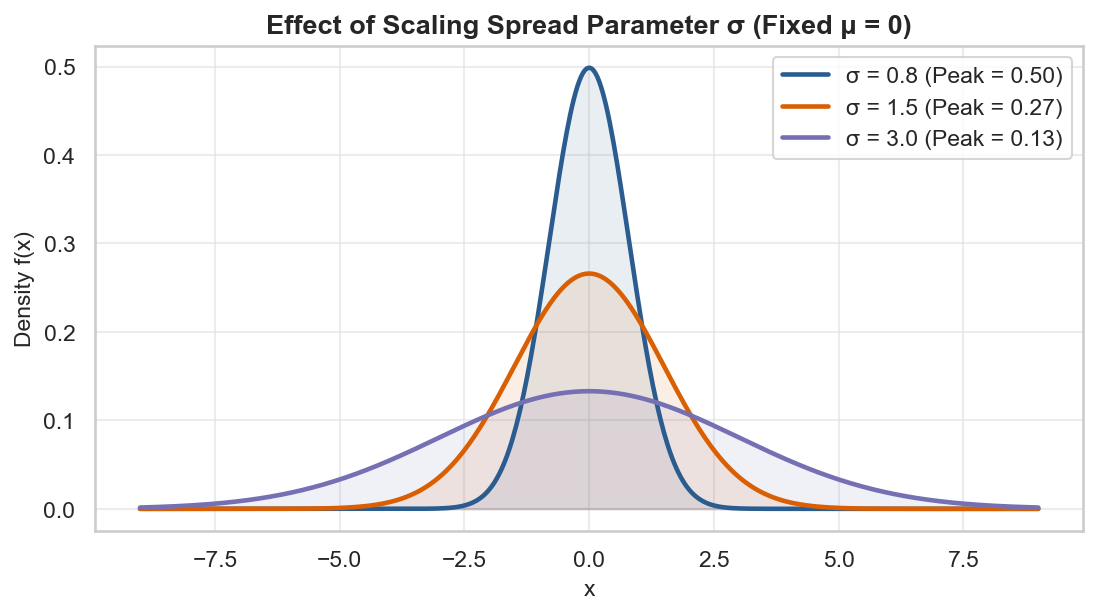

In [8]:
# Varying Standard Deviation sigma (Fixed mu = 0.0)
sigma_list = [0.8, 1.5, 3.0]
mu_zero = 0.0
x_eval_sig = np.linspace(-9, 9, 500)

fig, ax = plt.subplots(figsize=(8.5, 4.2))

for sig_val, col in zip(sigma_list, colors):
    pdf = stats.norm.pdf(x_eval_sig, loc=mu_zero, scale=sig_val)
    peak_h = 1.0 / (sig_val * np.sqrt(2 * np.pi))
    ax.plot(
        x_eval_sig,
        pdf,
        label=f"σ = {sig_val} (Peak = {peak_h:.2f})",
        color=col,
        linewidth=2.2,
    )
    ax.fill_between(x_eval_sig, pdf, color=col, alpha=0.1)

ax.set_title("Effect of Scaling Spread Parameter σ (Fixed μ = 0)", weight="bold")
ax.set_xlabel("x")
ax.set_ylabel("Density f(x)")
ax.legend(frameon=True)
plt.show()

## 5. Simulation & Law of Large Numbers

### Generating Normal Random Variables (The Box-Muller Transform)
Computers cannot use simple algebraic inversion because the normal CDF has no closed-form inverse. Instead, NumPy uses the **Box-Muller Transform** or **Ziggurat Algorithm**, transforming two independent $\mathcal{U}(0, 1)$ variables $(U_1, U_2)$ into standard normal draws:
$$Z_1 = \sqrt{-2\ln U_1}\cos(2\pi U_2), \quad Z_2 = \sqrt{-2\ln U_1}\sin(2\pi U_2)$$

### The Normal Q-Q Plot (Quantile-Quantile Plot)
The gold standard diagnostic test for normality in data science is the **Q-Q plot**: plotting sample empirical quantiles against theoretical Gaussian quantiles. If data is normal, the points form a perfectly straight diagonal line.

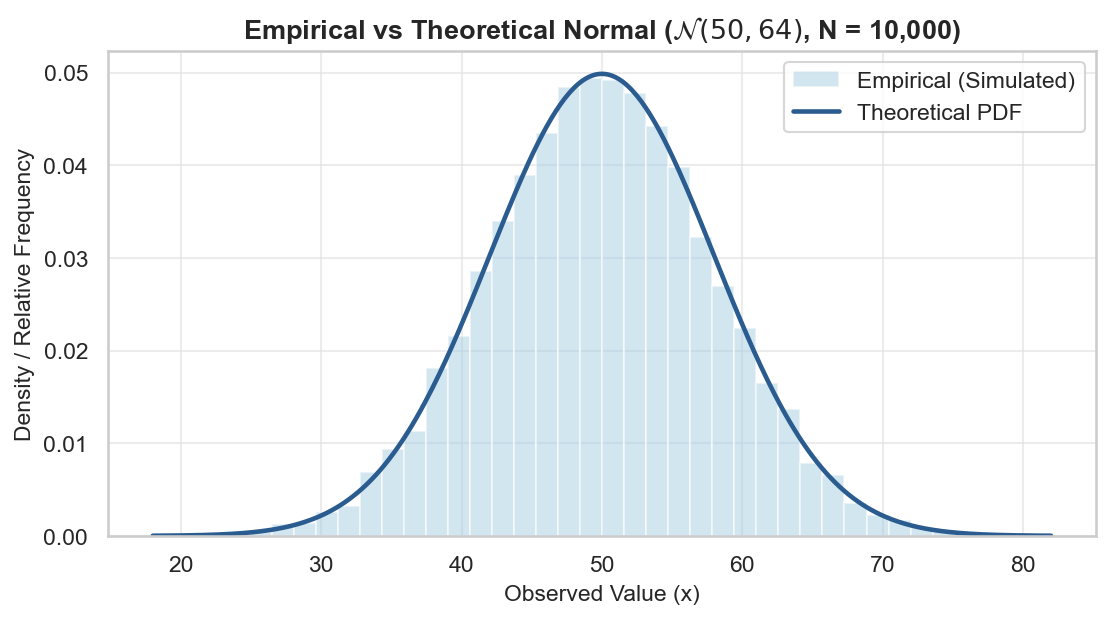

In [9]:
from utils.plotting import plot_sample_vs_theory

# Parameters: N(50, 8^2)
mu_sim = 50.0
sigma_sim = 8.0
sample_size = 10000

# Generate normal random variates
samples_norm = stats.norm.rvs(
    loc=mu_sim, scale=sigma_sim, size=sample_size, random_state=42
)

# Theoretical curve
x_th = np.linspace(mu_sim - 4 * sigma_sim, mu_sim + 4 * sigma_sim, 400)
pdf_th = stats.norm.pdf(x_th, loc=mu_sim, scale=sigma_sim)

# Plot empirical histogram vs theoretical PDF
fig, ax = plt.subplots(figsize=(8.5, 4.2))
plot_sample_vs_theory(
    samples=samples_norm,
    x_theory=x_th,
    y_theory=pdf_th,
    is_discrete=False,
    title=rf"Empirical vs Theoretical Normal ($\mathcal{{N}}({mu_sim:.0f}, {sigma_sim**2:.0f})$, N = {sample_size:,})",
    xlabel="Observed Value (x)",
    ax=ax,
)
plt.show()

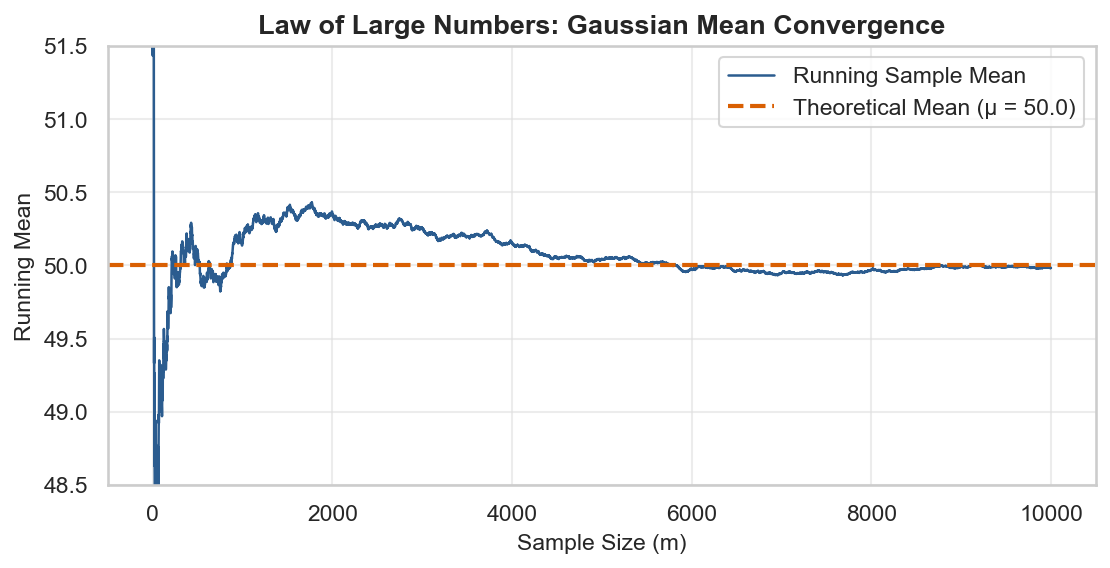

In [10]:
# Running mean convergence
running_m = np.cumsum(samples_norm) / np.arange(1, sample_size + 1)
plt.figure(figsize=(8.5, 3.8))
plt.plot(
    running_m,
    color=PALETTE["primary"],
    linewidth=1.2,
    label="Running Sample Mean",
)
plt.axhline(
    mu_sim,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=2,
    label=f"Theoretical Mean (μ = {mu_sim})",
)
plt.title("Law of Large Numbers: Gaussian Mean Convergence")
plt.xlabel("Sample Size (m)")
plt.ylabel("Running Mean")
plt.ylim(mu_sim - 1.5, mu_sim + 1.5)
plt.legend(frameon=True)
plt.show()

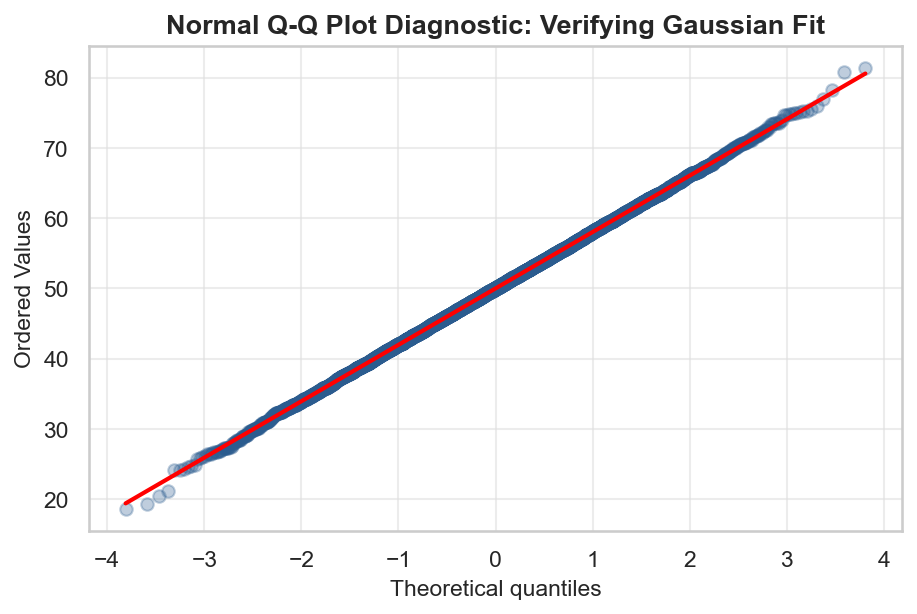

In [11]:
# Normal Quantile-Quantile (Q-Q) Plot Diagnostic
fig, ax = plt.subplots(figsize=(7, 4.2))
stats.probplot(samples_norm, dist="norm", plot=ax)

# Style Q-Q plot to match our theme
ax.get_lines()[0].set_markerfacecolor(PALETTE["primary"])
ax.get_lines()[0].set_color(PALETTE["primary"])
ax.get_lines()[0].set_alpha(0.3)
ax.get_lines()[1].set_color("red")
ax.get_lines()[1].set_linewidth(2)

ax.set_title("Normal Q-Q Plot Diagnostic: Verifying Gaussian Fit", weight="bold")
plt.show()

## 6. Applied Real-World Use Case: Industrial Quality Engineering & Six Sigma

### Scenario
A precision manufacturing plant produces ball bearings for aerospace jet engines.
The critical dimension is the outer diameter $X$ (in millimeters), which follows a Normal distribution:
$$X \sim \mathcal{N}(\mu = 25.000\text{ mm}, \, \sigma = 0.015\text{ mm})$$

### Engineering Specifications:
- **Nominal Target**: $T = 25.000$ mm
- **Lower Specification Limit (LSL)**: $24.960$ mm
- **Upper Specification Limit (USL)**: $25.040$ mm
- Tolerance window = $\pm 0.040$ mm.

### Process Capability Metrics:
1. **$C_p$ (Process Capability)**: Ratio of tolerance width to natural process spread ($6\sigma$):
   $$C_p = \frac{\text{USL} - \text{LSL}}{6\sigma}$$
2. **Defect Rate / Scrap PPM**: Parts Per Million defective falling outside $[\text{LSL}, \text{USL}]$.

In [12]:
mu_proc = 25.000
sigma_proc = 0.015
lsl = 24.960
usl = 25.040

# Process capability index Cp
tolerance_width = usl - lsl
cp = tolerance_width / (6 * sigma_proc)

# Scrap probabilities
p_under_lsl = stats.norm.cdf(lsl, loc=mu_proc, scale=sigma_proc)
p_over_usl = stats.norm.sf(usl, loc=mu_proc, scale=sigma_proc)
total_scrap_rate = p_under_lsl + p_over_usl
ppm_defective = total_scrap_rate * 1e6

print("--- SIX SIGMA PROCESS CAPABILITY REPORT ---")
print(f"Target Diameter:          {mu_proc:.3f} mm")
print(f"Tolerance Interval:       [{lsl:.3f}, {usl:.3f}] mm (Width = {tolerance_width:.3f} mm)")
print(f"Process Std Dev (σ):      {sigma_proc:.3f} mm\n")
print(f"Process Capability (Cp):  {cp:.3f} (Industry benchmark: >= 1.33)")
print(f"Yield (In-Spec):          {(1 - total_scrap_rate) * 100:.4f}%")
print(f"Scrap Rate (Out-of-Spec): {total_scrap_rate * 100:.4f}%")
print(f"Defect PPM:               {ppm_defective:.1f} parts per million")

--- SIX SIGMA PROCESS CAPABILITY REPORT ---
Target Diameter:          25.000 mm
Tolerance Interval:       [24.960, 25.040] mm (Width = 0.080 mm)
Process Std Dev (σ):      0.015 mm

Process Capability (Cp):  0.889 (Industry benchmark: >= 1.33)
Yield (In-Spec):          99.2339%
Scrap Rate (Out-of-Spec): 0.7661%
Defect PPM:               7660.8 parts per million


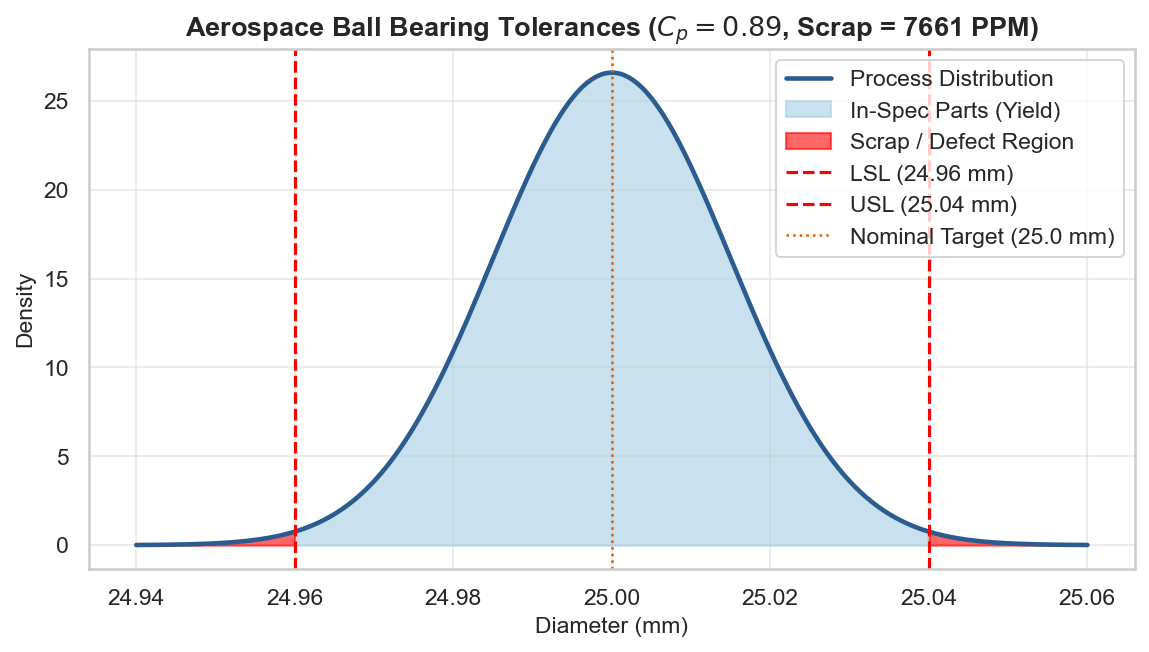

In [13]:
x_diam = np.linspace(24.94, 25.06, 500)
pdf_diam = stats.norm.pdf(x_diam, loc=mu_proc, scale=sigma_proc)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(x_diam, pdf_diam, color=PALETTE["primary"], linewidth=2.2, label="Process Distribution")

# In-spec region
mask_spec = (x_diam >= lsl) & (x_diam <= usl)
ax.fill_between(x_diam[mask_spec], pdf_diam[mask_spec], color=PALETTE["fill"], alpha=0.6, label="In-Spec Parts (Yield)")

# Scrap regions (Red)
mask_lsl = x_diam < lsl
mask_usl = x_diam > usl
ax.fill_between(x_diam[mask_lsl], pdf_diam[mask_lsl], color="red", alpha=0.6, label="Scrap / Defect Region")
ax.fill_between(x_diam[mask_usl], pdf_diam[mask_usl], color="red", alpha=0.6)

# Specification limit lines
ax.axvline(lsl, color="red", linestyle="--", linewidth=1.5, label=f"LSL ({lsl} mm)")
ax.axvline(usl, color="red", linestyle="--", linewidth=1.5, label=f"USL ({usl} mm)")
ax.axvline(mu_proc, color=PALETTE["secondary"], linestyle=":", linewidth=1.2, label=f"Nominal Target ({mu_proc} mm)")

ax.set_title(f"Aerospace Ball Bearing Tolerances ($C_p = {cp:.2f}$, Scrap = {ppm_defective:.0f} PPM)", weight="bold")
ax.set_xlabel("Diameter (mm)")
ax.set_ylabel("Density")
ax.legend(frameon=True, loc="upper right")
plt.show()

## 7. Parameter Estimation (Maximum Likelihood Estimation - MLE)

Given a sample of $N$ continuous measurements $x_1, x_2, \dots, x_N$:

### The Log-Likelihood Function
$$\ln L(\mu, \sigma^2) = -\frac{N}{2}\ln(2\pi) - \frac{N}{2}\ln(\sigma^2) - \frac{1}{2\sigma^2}\sum_{i=1}^{N}(x_i - \mu)^2$$

### Differentiating with Respect to $\mu$ and $\sigma^2$:
1. **MLE for Mean**:
   $$\frac{\partial \ln L}{\partial \mu} = \frac{1}{\sigma^2}\sum_{i=1}^N (x_i - \mu) = 0 \implies \hat{\mu}_{\text{MLE}} = \frac{1}{N}\sum_{i=1}^N x_i = \bar{x}$$
2. **MLE for Variance**:
   $$\frac{\partial \ln L}{\partial \sigma^2} = -\frac{N}{2\sigma^2} + \frac{1}{2(\sigma^2)^2}\sum_{i=1}^N (x_i - \mu)^2 = 0 \implies \hat{\sigma}^2_{\text{MLE}} = \frac{1}{N}\sum_{i=1}^{N}(x_i - \bar{x})^2$$

### The Bessel's Correction ($N$ vs $N - 1$)
The MLE for variance divides by $N$, which is **biased downward**:
$$\mathbb{E}[\hat{\sigma}^2_{\text{MLE}}] = \frac{N - 1}{N}\sigma^2$$
To obtain an unbiased estimator of population variance, we apply Bessel's correction:
$$s^2 = \frac{1}{N - 1}\sum_{i=1}^{N}(x_i - \bar{x})^2$$

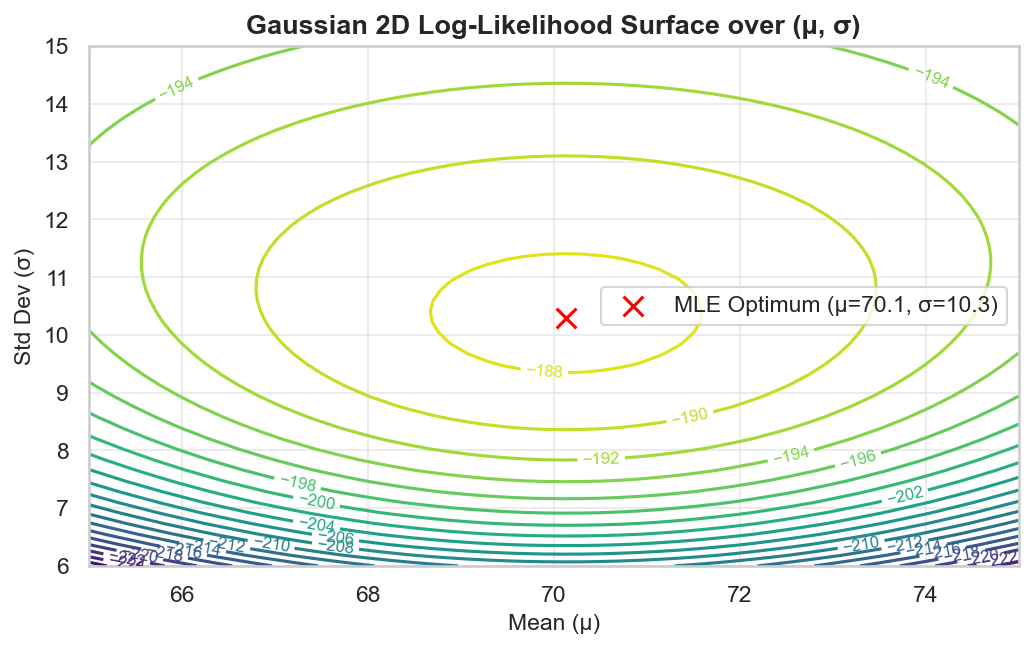

In [14]:
# True parameters
mu_true = 70.0  # e.g., human weight in kg
sigma_true = 10.0
N_sample = 50

# Generate observed continuous sample
obs_norm = stats.norm.rvs(
    loc=mu_true, scale=sigma_true, size=N_sample, random_state=777
)

# Analytical estimators
mu_mle = np.mean(obs_norm)
var_mle_biased = np.var(obs_norm, ddof=0)  # divided by N
var_unbiased = np.var(obs_norm, ddof=1)  # divided by N - 1

# 2D Log-Likelihood Contour Grid
mu_grid = np.linspace(65, 75, 50)
sig_grid = np.linspace(6, 15, 50)
M_mesh, S_mesh = np.meshgrid(mu_grid, sig_grid)


def gaussian_2d_log_lik(m, s, data):
    n = len(data)
    return (
        -n * np.log(s * np.sqrt(2 * np.pi))
        - np.sum((data - m) ** 2) / (2 * s**2)
    )


log_lik_map = np.zeros_like(M_mesh)
for i in range(M_mesh.shape[0]):
    for j in range(M_mesh.shape[1]):
        log_lik_map[i, j] = gaussian_2d_log_lik(
            M_mesh[i, j], S_mesh[i, j], obs_norm
        )

plt.figure(figsize=(8, 4.5))
contours = plt.contour(
    M_mesh, S_mesh, log_lik_map, levels=25, cmap="viridis"
)
plt.clabel(contours, inline=True, fontsize=8)
plt.scatter(
    [mu_mle],
    [np.sqrt(var_mle_biased)],
    color="red",
    s=90,
    zorder=5,
    marker="x",
    label=f"MLE Optimum (μ={mu_mle:.1f}, σ={np.sqrt(var_mle_biased):.1f})",
)
plt.title("Gaussian 2D Log-Likelihood Surface over (μ, σ)", weight="bold")
plt.xlabel("Mean (μ)")
plt.ylabel("Std Dev (σ)")
plt.legend(frameon=True)
plt.show()

In [15]:
# Standard error and confidence intervals
se_mean = np.sqrt(var_unbiased / N_sample)
ci_mu_low = mu_mle - 1.96 * se_mean
ci_mu_high = mu_mle + 1.96 * se_mean

print("--- GAUSSIAN ESTIMATION RESULTS ---")
print(f"Sample Size (N):               {N_sample}")
print(f"True Parameters:               μ = {mu_true:.2f}, σ = {sigma_true:.2f}\n")
print(f"Sample Mean (Analytical MLE):  {mu_mle:.4f}")
print(f"Biased MLE Variance (N):       {var_mle_biased:.4f}")
print(f"Unbiased Sample Variance (N-1):{var_unbiased:.4f}")
print(f"Standard Error of Mean:        {se_mean:.4f}")
print(f"95% CI for Mean:               [{ci_mu_low:.4f}, {ci_mu_high:.4f}]")

--- GAUSSIAN ESTIMATION RESULTS ---
Sample Size (N):               50
True Parameters:               μ = 70.00, σ = 10.00

Sample Mean (Analytical MLE):  70.1330
Biased MLE Variance (N):       105.8666
Unbiased Sample Variance (N-1):108.0272
Standard Error of Mean:        1.4699
95% CI for Mean:               [67.2521, 73.0140]


## 8. Related Distributions & Summary

The Normal distribution is the grand central terminal of all probability:

1. **Standard Normal ($Z \sim \mathcal{N}(0, 1)$)**:
   - Any Gaussian can be converted to $Z$ via standardization: $Z = \frac{X - \mu}{\sigma}$.
2. **Log-Normal Distribution**:
   - If $\ln(Y) \sim \mathcal{N}(\mu, \sigma^2)$, then $Y$ follows a **Log-Normal distribution** (multiplicative growth, stock prices).
3. **Chi-Square Distribution ($\chi^2$)**:
   - The square of a standard normal is a Chi-square variable with 1 degree of freedom: $Z^2 \sim \chi^2_1$.
   - Summing $k$ independent squared standard normals yields $\sum_{i=1}^k Z_i^2 \sim \chi^2_k$.
4. **Student's t-Distribution**:
   - When estimating the mean of a normal distribution with an **unknown variance** from a small sample, the standardized statistic follows a Student's t-distribution: $T = \frac{\bar{X} - \mu}{s / \sqrt{N}} \sim t_{N-1}$.
5. **The Central Limit Theorem Attractor**:
   - The sum or average of independent variables from *any* distribution with finite variance converges to a Normal distribution!

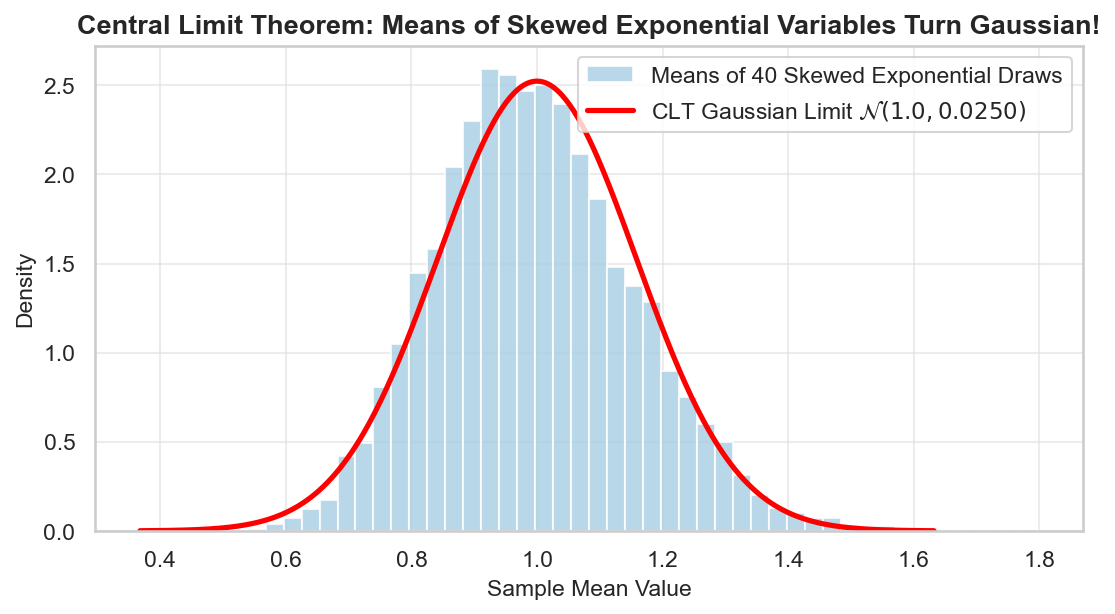

In [16]:
# Demonstrating Central Limit Theorem:
# Summing 40 heavily skewed Exponential random variables (lambda = 1.0)
n_summands = 40
n_trials_clt = 10000

# Exponential draws are heavily skewed (skewness = 2.0)
exp_samples = stats.expon.rvs(scale=1.0, size=(n_trials_clt, n_summands))

# Compute sample means of 40 exponential draws
sample_means = np.mean(exp_samples, axis=1)

# Theoretical mean and std dev of sample mean by CLT
mu_exp = 1.0
se_exp = 1.0 / np.sqrt(n_summands)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
x_clt_eval = np.linspace(mu_exp - 4 * se_exp, mu_exp + 4 * se_exp, 400)
pdf_clt_norm = stats.norm.pdf(x_clt_eval, loc=mu_exp, scale=se_exp)

ax.hist(
    sample_means,
    bins=45,
    density=True,
    color=PALETTE["fill"],
    edgecolor="white",
    alpha=0.8,
    label=f"Means of {n_summands} Skewed Exponential Draws",
)
ax.plot(
    x_clt_eval,
    pdf_clt_norm,
    color="red",
    linewidth=2.5,
    label=rf"CLT Gaussian Limit $\mathcal{{N}}({mu_exp}, {se_exp**2:.4f})$",
)

ax.set_title("Central Limit Theorem: Means of Skewed Exponential Variables Turn Gaussian!", weight="bold")
ax.set_xlabel("Sample Mean Value")
ax.set_ylabel("Density")
ax.legend(frameon=True)
plt.show()

### Summary Card: Normal (Gaussian) Distribution

| Property | Formulation |
| :--- | :--- |
| **Notation** | $X \sim \mathcal{N}(\mu, \sigma^2)$ |
| **Parameters** | $\mu \in \mathbb{R}$ (mean), $\sigma > 0$ (standard deviation; $\sigma^2$ is variance) |
| **Support** | $x \in (-\infty, +\infty)$ |
| **PDF** | $f(x) = \frac{1}{\sigma \sqrt{2\pi}} \exp\left(-\frac{(x - \mu)^2}{2\sigma^2}\right)$ |
| **CDF** | $F(x) = \frac{1}{2}\left[1 + \text{erf}\left(\frac{x - \mu}{\sigma\sqrt{2}}\right)\right]$ |
| **Mean ($\mu$)** | $\mu$ (Coincides with Median and Mode) |
| **Variance ($\sigma^2$)** | $\sigma^2$ |
| **Skewness ($\gamma_1$)** | $0$ (Strictly symmetric) |
| **Excess Kurtosis ($\gamma_2$)** | $0$ (Mesokurtic baseline) |
| **MLE Estimators** | $\hat{\mu} = \bar{x}$, $\hat{\sigma}^2_{\text{MLE}} = \frac{1}{N}\sum (x_i - \bar{x})^2$ (Bessel's correction uses $N-1$) |
| **Key Property** | 68–95–99.7 Empirical Rule; Inflection points at $\mu \pm \sigma$ |
| **Key Use Cases** | Industrial Six Sigma tolerances, measurement errors, regression residuals, baseline CLT |